STEP 1

Analyical : Alpha = -2.4006676378196277 Beta = -1.6075025166709007
Numerical : Alpha = -2.3946553634482717 +- 0.23476058980939304 Beta = -1.6086476401548073 +- 0.20417603094292708



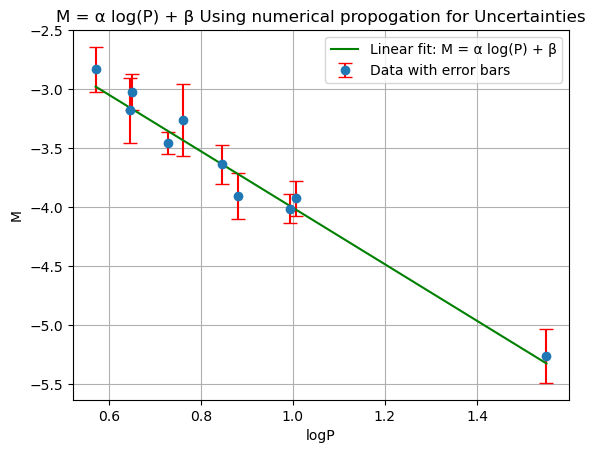


Chi-squared: 4.313790892538417
Expected chi =  8 +- 4.0
Reduced chi-squared: 0.5392238615673022

STEP 2

Distance of ngc4527 in parcecs without removing outliers:  15065052.171379669 +- 561986.0896824673 pc



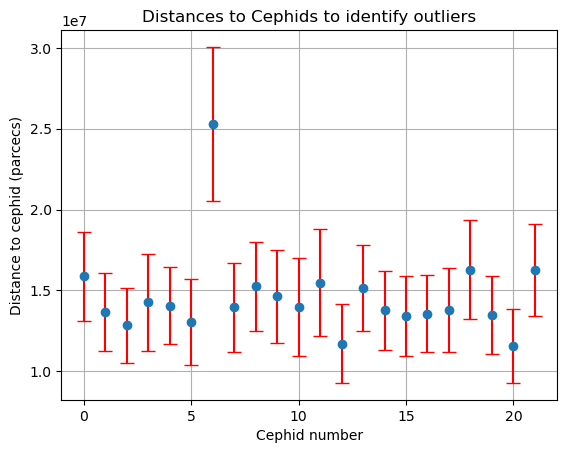


Outliers in the distance data: [6] ([25285593.68760049] parcecs)  Value removed from the distance data
Distance of ngc4527 after removing outliers:  14190042.018393675 +- 268959.54616897897 pc

Hubble Constant for ngc4527 = 81.18369195149201 +- 1.5387642203801764 (km/s)/Mpc

STEP 3



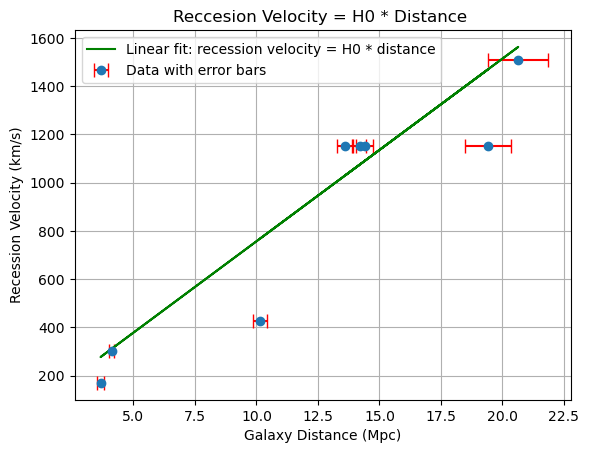

Chi-squared: 433.60032329001837
Expected chi =  7 +- 3.7416573867739413
Reduced chi-squared: 61.94290332714548

Hubble constant obtained from the graph :  75.72092245406085 +- 5.741928747708192 (km/s)/Mpc
Hubble constant obtained from the average each galaxies individual H0:  68.98720933679643 +- 5.4036904186937535 (km/s)/Mpc


In [6]:
import math
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

#########################################################STEP 1##########################################################################################
print("STEP 1")
print("")

# Reading text File 

para , para_unc , pulse_period , m , ext , ext_unc = np.loadtxt("MW_Cepheids.dat" , unpack = True , dtype = float , usecols = (1,2,3,4,5,6))

# Calculating distance and Uncertainties

dist = np.array(1000/para)
dist_unc = np.array((1000/para**2)*para_unc)

# Calculating Absolute Mag

M = np.empty(len(m))
for i in range(len(m)):
    M[i] = (m[i] - (5 * np.log10(dist[i])) + 5 - ext[i])

# Calc uncertainty in M analyticly

M_unc_an = np.empty(len(m))
for i in range(len(M)):
    M_unc_an[i] = (  np.sqrt(  (((5/(dist[i]*np.log(10)))*dist_unc[i])**2) + (ext_unc[i])**2  )   )


# Calculating log(pulse period)

logP = np.empty(len(m))
for i in range(len(pulse_period)):
    logP[i] = (np.log10(pulse_period[i]))

# Getting Alpha and Beta from analytical data

def func_M(logP,alpha,beta):
    """Function to define an equation for a graph of M = alpha*logP + beta:
    Inputs: logP , alpha , beta - float values that find respective y values from x values
    Outputs: line_M - float y values to be graphed.  """ 
    line_M = alpha * logP + beta
    return line_M

popt , pcov  = curve_fit(f=func_M , xdata=logP , ydata=M , sigma=M_unc_an , absolute_sigma=True )

alpha = popt[0]
beta = popt[1]
print("Analyical : Alpha =",alpha,"Beta =",beta)


# Plotting Analytical data
 
"""plt.errorbar(logP , M , yerr = M_unc_an , fmt="o" , capsize = 5, ecolor = "red")
plt.xlabel('logP')
plt.ylabel('M')
plt.title("Analytical")
plt.plot(logP, alpha*logP + beta , color='green')
#plt.legend()
plt.grid(True)
plt.show()
print("")"""

# Unc in M numericaly

M_mean = np.empty(len(m))
M_std = np.empty(len(m))
for i in range(len(m)):
    mean_d = dist[i]
    std_d = dist_unc[i]
    draw_d = np.random.normal(mean_d,std_d,10000)
    mean_ext = ext[i]
    std_ext = ext_unc[i]
    draw_ext = np.random.normal(mean_ext,std_ext,10000)
    M_values = (m[i] - (5 * np.log10(draw_d)) + 5 - draw_ext)
    M_mean[i] = np.mean(M_values)
    M_std[i] = np.std(M_values)



# Finding Allpha and beta Numericly with uncertainties

popt , pcov  = curve_fit(f=func_M , xdata=logP , ydata=M_mean , sigma=M_std , absolute_sigma=True )
alpha = popt[0]
beta = popt[1]
alpha_unc = np.sqrt(pcov[0,0])
beta_unc = np.sqrt(pcov[1,1])


print("Numerical : Alpha =",alpha,"+-",alpha_unc,"Beta =",beta,"+-",beta_unc)
print("")


# Plotting numerical data

plt.errorbar(logP , M_mean , yerr = M_std , fmt="o" , capsize = 5, ecolor = "red" , label="Data with error bars")
plt.xlabel('logP')
plt.ylabel('M')
plt.title("M = α log(P) + β Using numerical propogation for Uncertainties")
plt.plot(logP, alpha*logP + beta , color='green', label="Linear fit: M = α log(P) + β")
plt.legend()
plt.grid()
plt.show()
print("")

# Chi squared test for the fit

M_expected = func_M(logP, alpha, beta)


chi_squared = 0

for i in range (len(M_mean)):
    chi_squared = chi_squared + (((M_mean[i] - M_expected[i]) / (M_std[i])) ** 2)


dof_ab = len(M_mean) - 2  # Number of data points - number of parameters (alpha, beta)

chi_squared_reduced = chi_squared / dof_ab


print(f"Chi-squared: {chi_squared}")
print("Expected chi = ",dof_ab,"+-",np.sqrt(2*dof_ab))
print(f"Reduced chi-squared: {chi_squared_reduced}")
print("")

#########################################################STEP 2##########################################################################################
print("STEP 2")
print("")

# Calculating distance from cephid data and values for alpha and beta

ceph_logP , ceph_m = np.loadtxt("ngc4527_cepheids.dat" , unpack = True , dtype = float , usecols = (1,2))

# Numerical values and uncertaintys for M 

M_mean_ceph = np.empty(len(ceph_logP))
M_std_ceph = np.empty(len(ceph_logP))
for i in range(len(ceph_logP)):
    draw_alpha = np.random.normal(alpha,alpha_unc,10000)
    draw_beta = np.random.normal(beta,beta_unc,10000)
    M_values_ceph = (  (draw_alpha * ceph_logP[i] )  + draw_beta )
    M_mean_ceph[i] = np.mean(M_values_ceph)
    M_std_ceph[i] = np.std(M_values_ceph)

# Numerical values and uncertaintys for d using previous M values

d_mean_ceph = np.empty(len(ceph_logP))
d_std_ceph = np.empty(len(ceph_logP))
for i in range(len(ceph_logP)):
    draw_M = np.random.normal(M_mean_ceph[i],M_std_ceph[i],10000)  
    d_values_ceph = ( 10**(     (draw_M + 0.0682 - 5 - ceph_m[i])/(-5)    )   )
    d_mean_ceph[i] = np.mean(d_values_ceph)
    d_std_ceph[i] = np.std(d_values_ceph)




# Finding mean distance with its error

mean_dist = np.average(d_mean_ceph, weights = d_std_ceph) # weighted mean using the uncertainties
standard_error_dist = np.std(d_mean_ceph/np.sqrt(len(ceph_m)))

print("Distance of ngc4527 in parcecs without removing outliers: ",mean_dist,"+-",  standard_error_dist,"pc")
print("")

# Plotting distances to see outliers

plt.errorbar(list(range(len(d_mean_ceph))),d_mean_ceph, yerr = d_std_ceph , fmt="o" , capsize = 5, ecolor = "red" , )
plt.xlabel('Cephid number')
plt.ylabel('Distance to cephid (parcecs)')
plt.title("Distances to Cephids to identify outliers")
plt.grid()
plt.show()
print("")



# Calculating outliers in the data unsing the inter quartile range method

Q1 = np.percentile(d_mean_ceph, 25)
Q2 = np.percentile(d_mean_ceph, 50)
Q3 = np.percentile(d_mean_ceph, 75)
IQR = Q3 - Q1

outliers_d = []
for i in range (len(d_mean_ceph)):
    if (d_mean_ceph[i] > (Q2 + 1.5*IQR)) or (d_mean_ceph[i] < (Q2 - 1.5*IQR)):
        outliers_d.append(i) 

print(f"Outliers in the distance data: {outliers_d} ({d_mean_ceph[outliers_d]} parcecs)  Value removed from the distance data")

# Removing the outliers from the data for cephid distance

for i in range(len(outliers_d)):
    d_mean_ceph =  np.delete(d_mean_ceph,outliers_d[i])
    d_std_ceph =  np.delete(d_std_ceph,outliers_d[i])

# Finding mean distance with its error after removing outliers

mean_dist_after_out = np.average(d_mean_ceph, weights = d_std_ceph) # weighted mean using uncertainties
standard_error_dist_after_out = np.std(d_mean_ceph)/np.sqrt(len(ceph_m))

print("Distance of ngc4527 after removing outliers: ",mean_dist_after_out,"+-",  standard_error_dist_after_out,"pc")
print("")

# Calculating hubble constant for ngc4527

v_rec = 1152 
mean_dist_Mpc = mean_dist_after_out/1e6   # converting to mega parcecs from parcecs
standard_error_dist_Mpc = standard_error_dist_after_out/1e6

H0_ngc4527 = v_rec / mean_dist_Mpc

H0_unc_ngc4527 = ((v_rec/mean_dist_Mpc**2)*standard_error_dist_Mpc) # error propogation to get uncertainty 

print("Hubble Constant for ngc4527 =",H0_ngc4527,"+-", H0_unc_ngc4527,"(km/s)/Mpc")
print("")
        
        


#########################################################STEP 3##########################################################################################
print("STEP 3")
print("")

# Other Galaxies hubble constant

rec_vel , gal_dist , gal_dist_unc = np.loadtxt("other_galaxies.dat" , unpack = True , dtype = float , usecols = (1,2,3))

# Adding the distance and recession velocity of ngc4527 in to the data set

rec_vel = np.append(rec_vel,1152)
gal_dist = np.append(gal_dist,mean_dist_Mpc)
gal_dist_unc = np.append(gal_dist_unc,standard_error_dist_Mpc)


# Value of H0 for each galaxy and its error numericly

H0_mean_gal = np.empty(len(gal_dist))
H0_std_gal = np.empty(len(gal_dist))
for i in range(len(rec_vel)):
    draw_d_gal = np.random.normal(gal_dist[i],gal_dist_unc[i],10000)  
    H0_values_gal = ( rec_vel[i] / draw_d_gal  )
    H0_mean_gal[i] = np.mean(H0_values_gal)
    H0_std_gal[i] = np.std(H0_values_gal)

H0_numerical_mean =  np.average(H0_mean_gal,weights = H0_std_gal)   
standard_error_H0 = (np.std(H0_mean_gal))/(np.sqrt(len(H0_mean_gal)))



# Plotting rec vel against galaxy distance to obtain a value for H0

def func_H0(g,rec_vel):
    """Function to define an equation for a graph of Distance = g*rec_vel:
    Inputs: g , rec_vel - float values that find respective y values from x values
    Outputs: line_d - float y values to be graphed."""  
    line_d = g * rec_vel
    return line_d

popt , pcov = curve_fit(f=func_H0 , xdata=rec_vel , ydata=gal_dist , sigma=gal_dist_unc)

g = popt[0]

H0 = 1/g

H0_unc = (1/g**2)*np.sqrt(pcov[0,0]) #error propogation to change the uncertainty in gradient into the uncertaintiy in hubble constant



plt.errorbar(gal_dist , rec_vel , xerr = gal_dist_unc , fmt="o" , capsize = 5, ecolor = "red" , label="Data with error bars")
plt.xlabel('Galaxy Distance (Mpc)')
plt.ylabel('Recession Velocity (km/s)')
plt.title("Reccesion Velocity = H0 * Distance ")
plt.plot(gal_dist, H0 * gal_dist, color='green', label="Linear fit: recession velocity = H0 * distance")
plt.legend()
plt.grid()
plt.show()

# Chi squared for hubble constant  plot

d_expected = func_H0(g,rec_vel)


chi_squared = 0

for i in range (len(gal_dist)):
    chi_squared = chi_squared + ((((gal_dist[i]) - d_expected[i]) / (gal_dist_unc[i])) ** 2)


dof_H0 = len(gal_dist) - 1  # Number of data points - number of parameters (H0)

chi_squared_reduced = chi_squared / dof_H0



print(f"Chi-squared: {chi_squared}")
print("Expected chi = ",dof_H0,"+-",np.sqrt(2*dof_H0))  #if chi is above expected uncertainties are underestimated
print(f"Reduced chi-squared: {chi_squared_reduced}")
print("")


print("Hubble constant obtained from the graph : ",H0,"+-",H0_unc,"(km/s)/Mpc")
print("Hubble constant obtained from the average each galaxies individual H0: ",H0_numerical_mean,"+-",standard_error_H0,"(km/s)/Mpc")


11
